# Work-location periods
How many individuals have a work location (Wikidata P937), and how many of those workplaces carry a work period (start P580 and end P582), overall and by century of birth.

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
from style import *

apply_style()

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only
STATEMENTS = Path('../../data/raw_data_from_wikidata/wikidata_extraction_scripts_v2/life_locations/parts/statements')
MIN_BORN = 1_000  # centuries with fewer births are left out of the per-century views
STATUSES = {
    'every workplace has a period': GREEN,
    'some workplaces have a period': LIGHT_GREEN,
    'dated, no period': LIGHT_ORANGE,
    'no date': LIGHT_GREY,
}

pl.Config.set_tbl_rows(50)
pl.Config.set_tbl_width_chars(250)
pl.Config.set_tbl_hide_column_data_types(True)

polars.config.Config

## Data
One row per non-deprecated work-location statement: a **period** has both a start and an end; a statement is **dated** if it has a start, an end or a point in time. Every individual of the database comes with their birth year.

In [2]:
connection = duckdb.connect(DB_PATH, read_only=True)
date = 'STRUCT(time VARCHAR, precision INTEGER)'
work_locations = connection.sql(f'''
    SELECT qid, target, start IS NOT NULL AND "end" IS NOT NULL AS period,
           start IS NOT NULL OR "end" IS NOT NULL OR point_in_time IS NOT NULL AS dated
    FROM read_json('{STATEMENTS}/*.json', columns = {{qid: 'VARCHAR', property: 'VARCHAR', target: 'VARCHAR', rank: 'VARCHAR',
                                                       start: '{date}', "end": '{date}', point_in_time: '{date}'}})
    WHERE property = 'P937' AND rank <> 'deprecated'
''').pl()
individuals = connection.sql('SELECT entity.qid AS qid, birth_date.year AS birth FROM individual_enriched').pl()
assert individuals['qid'].is_unique
assert work_locations['qid'].is_in(individuals['qid'].implode()).all()
print(f'{work_locations.height:,} work-location statements of {work_locations["qid"].n_unique():,} individuals; {individuals.height:,} individuals in the database')
work_locations.sample(5, seed=0)

587,713 work-location statements of 452,295 individuals; 13,002,897 individuals in the database


qid,target,period,dated
"""Q13471284""","""Q220""",false,false
"""Q14106938""","""Q1643355""",false,false
"""Q137340219""","""Q659900""",false,false
"""Q10306836""","""Q2844""",false,false
"""Q18122918""","""Q84""",false,false


### One status per individual
Over all the work locations of an individual.

In [3]:
people = (
    work_locations.group_by('qid')
    .agg(pl.len().alias('workplaces'), pl.col('period').sum().alias('periods'), pl.col('dated').any())
    .with_columns(
        status=pl.when(pl.col('periods') == pl.col('workplaces')).then(pl.lit('every workplace has a period'))
        .when(pl.col('periods') > 0).then(pl.lit('some workplaces have a period'))
        .when(pl.col('dated')).then(pl.lit('dated, no period'))
        .otherwise(pl.lit('no date'))
    )
    .join(individuals, on='qid')
)
assert people.height == work_locations['qid'].n_unique()
people.sample(5, seed=0)

qid,workplaces,periods,dated,status,birth
"""Q133325240""",1,0,false,"""no date""",null
"""Q137770663""",1,0,false,"""no date""",null
"""Q136160406""",1,0,false,"""no date""",null
"""Q10307070""",1,0,false,"""no date""",1846
"""Q17195285""",1,0,false,"""no date""",1823


## Overall

452,295 individuals have a work location (3.5% of the database)


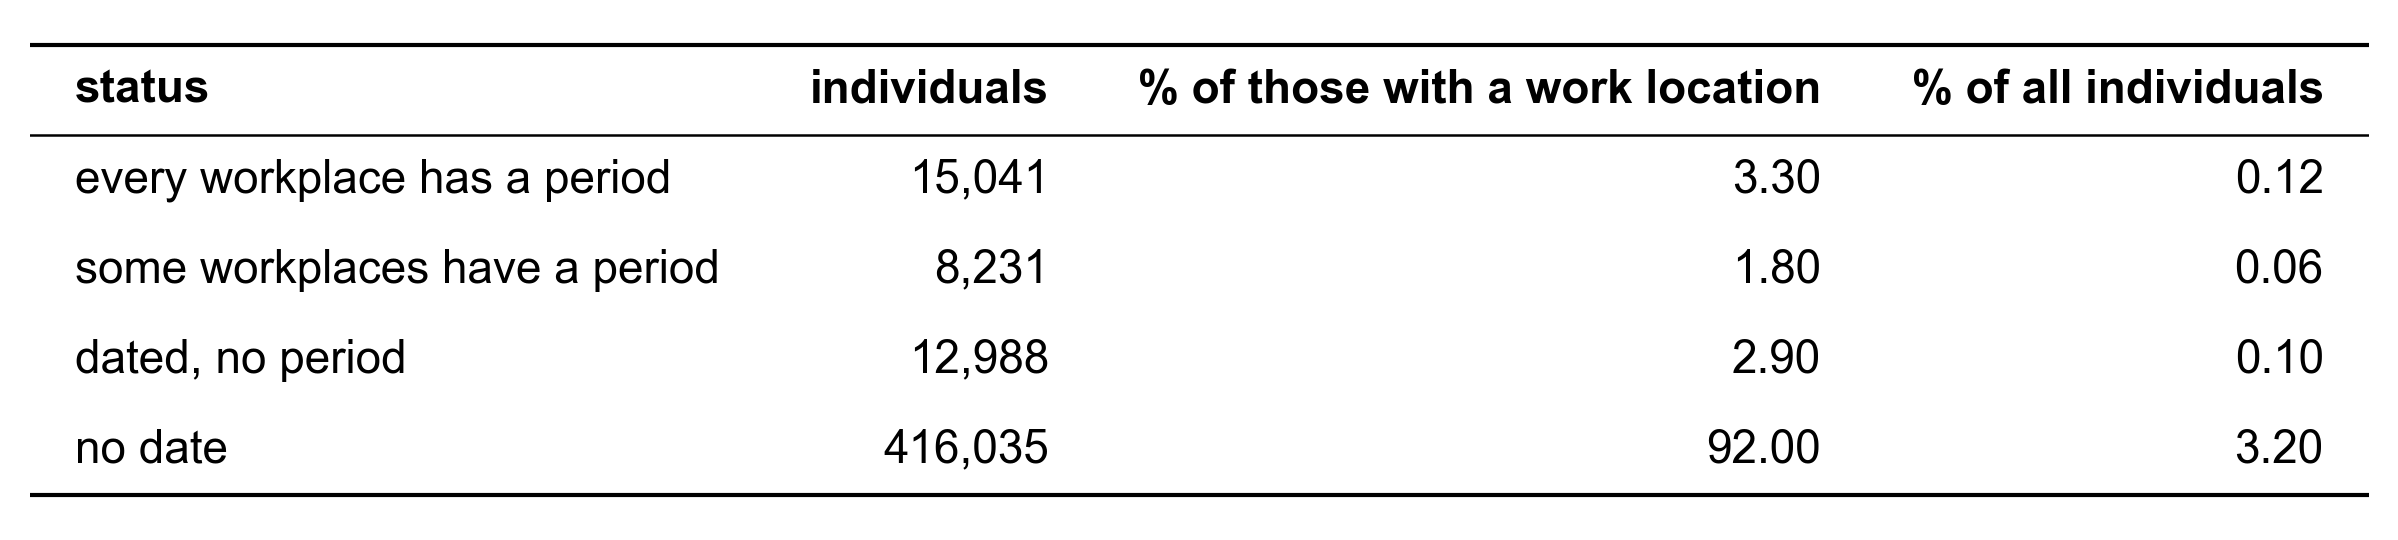

In [4]:
overall = (
    people.group_by('status').len('individuals')
    .with_columns(
        (100 * pl.col('individuals') / people.height).round(1).alias('% of those with a work location'),
        (100 * pl.col('individuals') / individuals.height).round(2).alias('% of all individuals'),
    )
    .sort(pl.col('status').cast(pl.Enum(list(STATUSES))))
)
print(f'{people.height:,} individuals have a work location ({100 * people.height / individuals.height:.1f}% of the database)')
show_table(overall)

## By century of birth
Individuals without a birth year are left out here.

In [5]:
def century(year):
    number = abs(year) // 100 + 1 if year >= 0 else (abs(year) - 1) // 100 + 1
    suffix = 'th' if 10 <= number % 100 <= 20 else {1: 'st', 2: 'nd', 3: 'rd'}.get(number % 10, 'th')
    return f"{number}{suffix} c.{' BC' if year < 0 else ''}"


order = pl.when(pl.col('birth') >= 0).then(pl.col('birth') // 100).otherwise(-((-pl.col('birth') - 1) // 100) - 1).alias('order')
born = individuals.drop_nulls('birth').group_by(order).agg(pl.len().alias('born'), pl.col('birth').first())
per_status = people.drop_nulls('birth').group_by(order, 'status').len().pivot(on='status', index='order', values='len')
per_century = (
    born.join(per_status, on='order', how='left').fill_null(0)
    .filter(pl.col('born') >= MIN_BORN)
    .sort('order')
    .with_columns(
        pl.col('birth').map_elements(century, return_dtype=pl.String).alias('century'),
        pl.sum_horizontal(list(STATUSES)).alias('with work location'),
    )
)
print(f'{individuals["birth"].null_count():,} individuals without a birth year left out; '
      f'{per_century.height} centuries with at least {MIN_BORN:,} births kept, out of {born.height}')
per_century.select('century', 'born', 'with work location', *STATUSES).head()

5,361,546 individuals without a birth year left out; 20 centuries with at least 1,000 births kept, out of 56


century,born,with work location,every workplace has a period,some workplaces have a period,"dated, no period",no date
"""2nd c.""",1316,21,0,0,0,21
"""3rd c.""",1718,35,0,0,0,35
"""4th c.""",1810,36,0,0,0,36
"""5th c.""",2706,33,0,0,0,33
"""6th c.""",5696,42,0,0,0,42


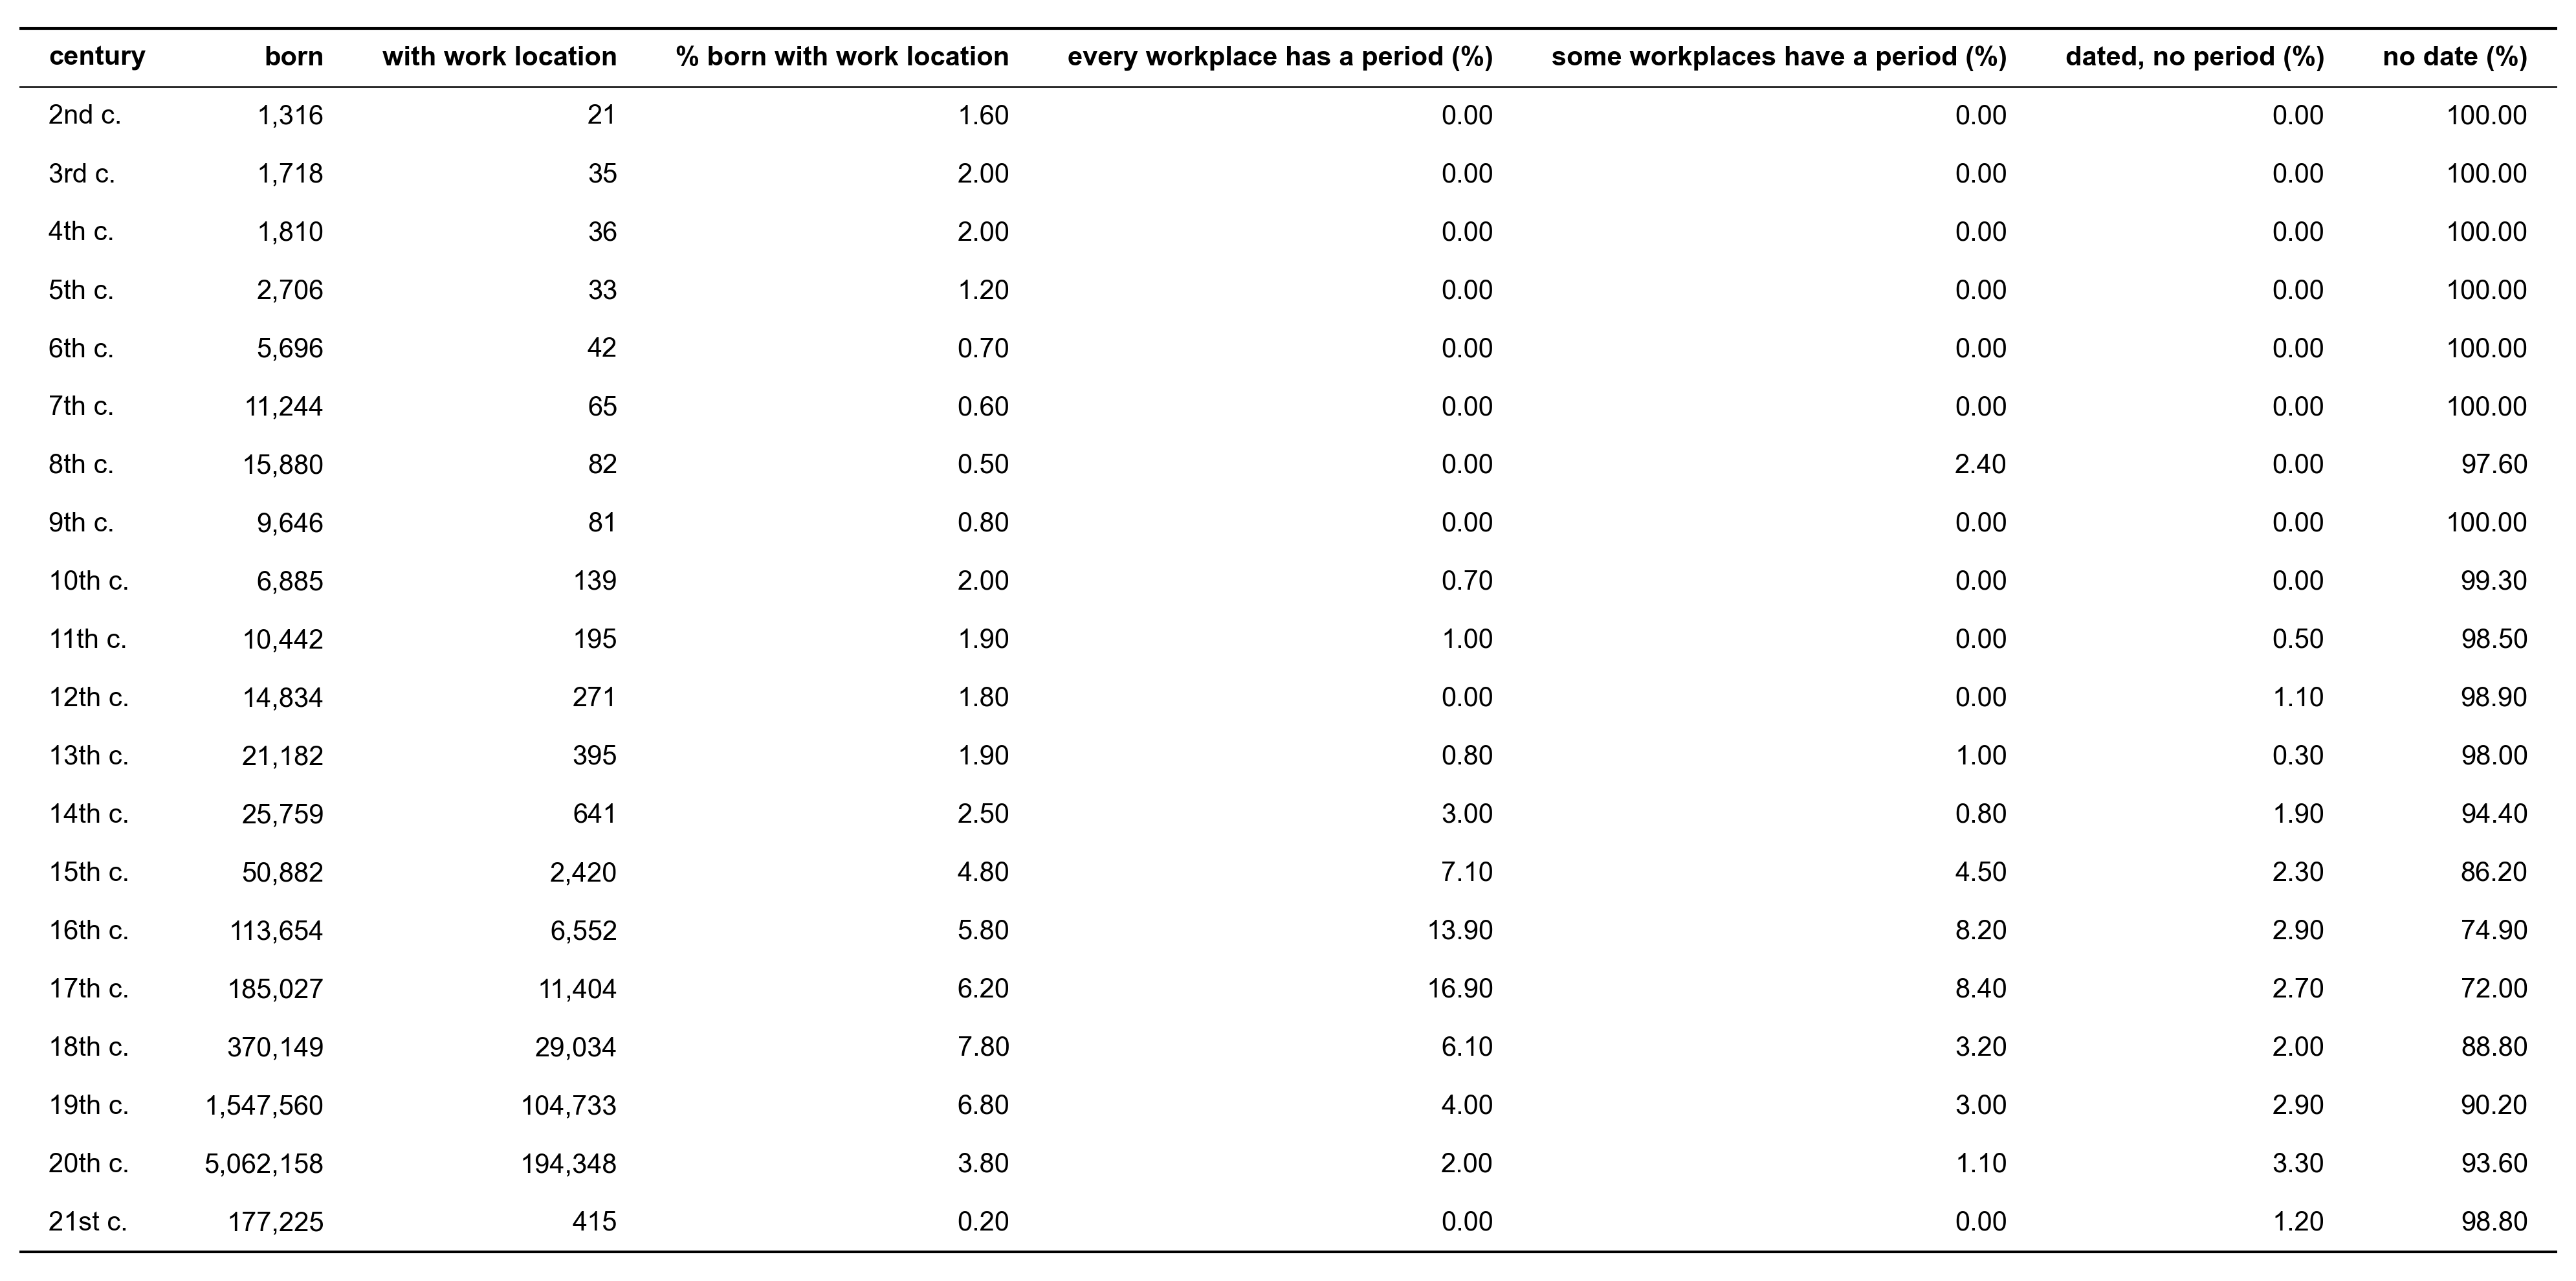

In [6]:
table = per_century.select(
    'century', 'born', 'with work location',
    (100 * pl.col('with work location') / pl.col('born')).round(1).alias('% born with work location'),
    *[(100 * pl.col(status) / pl.col('with work location')).round(1).alias(f'{status} (%)') for status in STATUSES],
)
show_table(table, font_size=10)

### Figure 1: Share of individuals born in each century with a work location, and with a work period

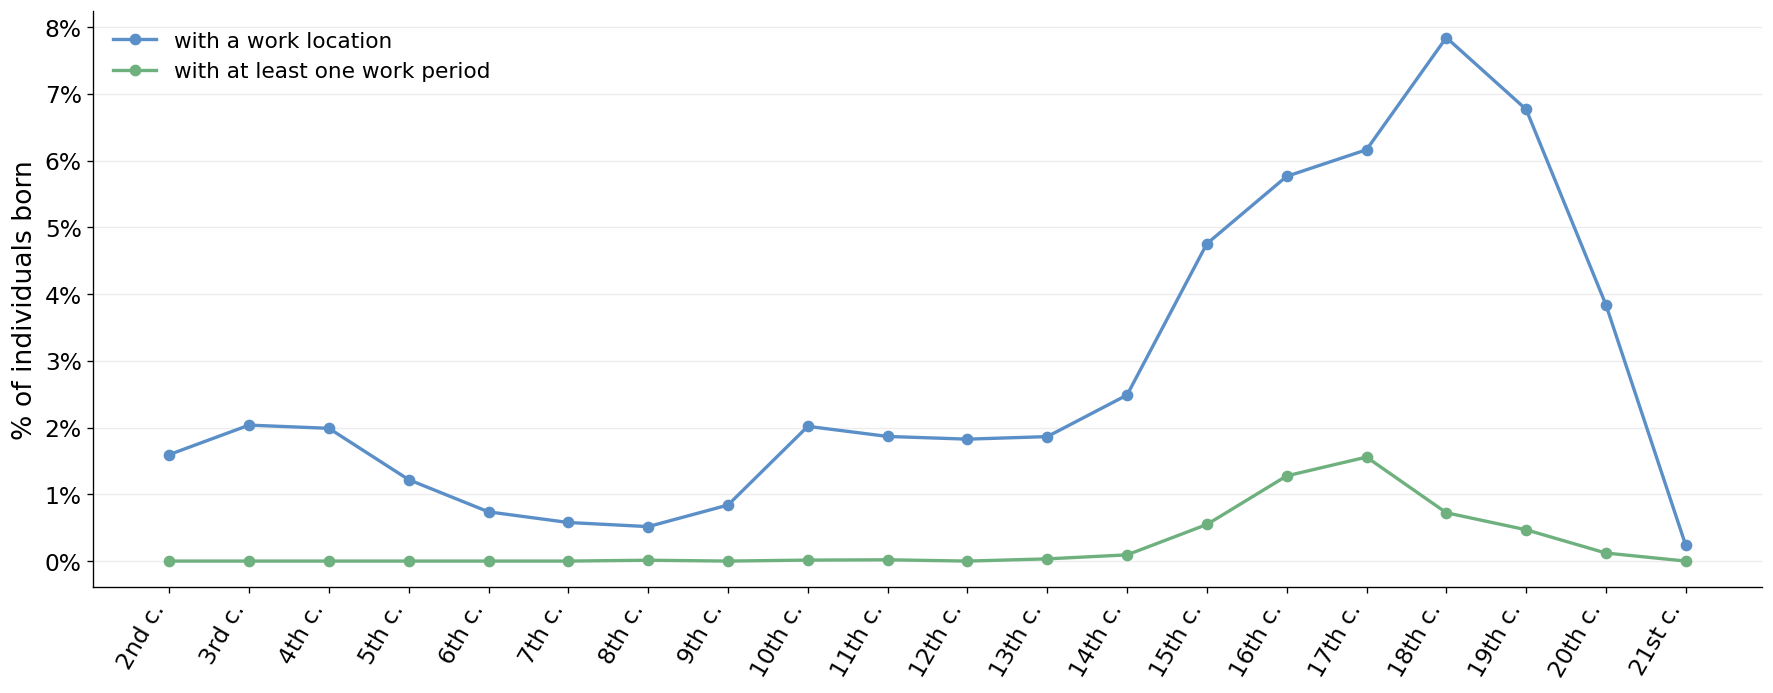

In [7]:
x = range(per_century.height)
with_period = per_century['every workplace has a period'] + per_century['some workplaces have a period']
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
ax.plot(x, 100 * per_century['with work location'] / per_century['born'], color=BLUE, marker='o', label='with a work location')
ax.plot(x, 100 * with_period / per_century['born'], color=GREEN, marker='o', label='with at least one work period')
ax.set_xticks(x, per_century['century'], rotation=60, ha='right')
ax.set_ylabel('% of individuals born')
ax.yaxis.set_major_formatter(PERCENT)
ax.grid(axis='y')
ax.legend()
plt.tight_layout()
plt.show()

### Figure 2: Dating of work locations by century of birth (% of individuals with a work location)

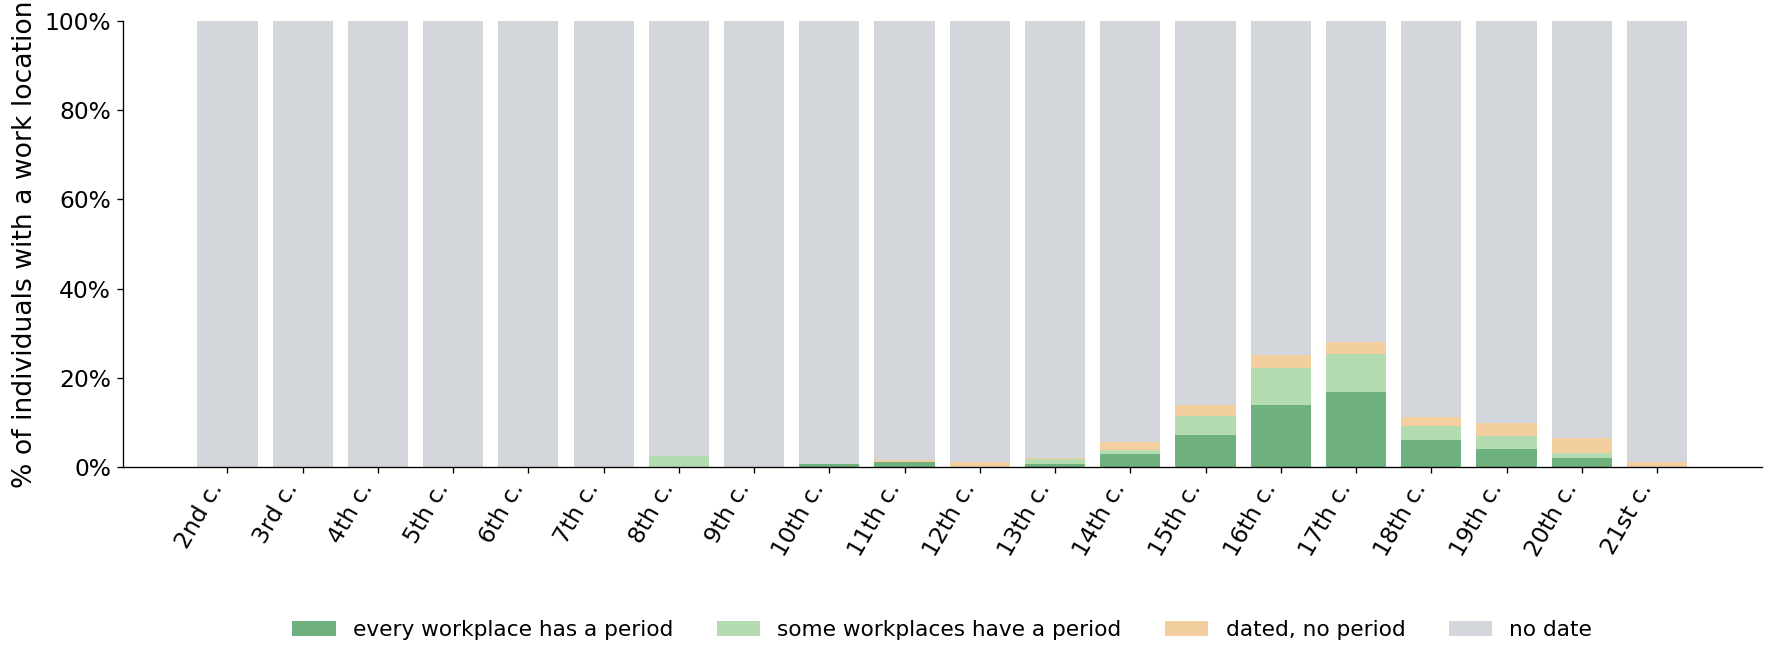

In [8]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
bottom = [0.0] * per_century.height
for status, color in STATUSES.items():
    share = (100 * per_century[status] / per_century['with work location']).fill_nan(0).to_list()
    ax.bar(x, share, bottom=bottom, color=color, label=status, width=0.8)
    bottom = [low + value for low, value in zip(bottom, share)]
ax.set_xticks(x, per_century['century'], rotation=60, ha='right')
ax.set_ylabel('% of individuals with a work location')
ax.yaxis.set_major_formatter(PERCENT)
ax.set_ylim(0, 100)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=4)
plt.tight_layout()
plt.show()